# El ave más ruidosa depende de cuánto la escucho

## Un EDA para entender qué significa realmente batir un récord de sonido

> **Pregunta:** ¿sigue ganando la misma especie cuando comparo a todas con el mismo número de lecturas?

**Categoría obligatoria: EDA (análisis exploratorio de datos).**

Este notebook parte del conjunto de datos de Menezes y Podos, pero plantea una pregunta distinta a la noticia original. No busco repetir que existen nuevas candidatas al récord. Analizo cuánto depende ese récord de la forma de medir y del número de oportunidades que tuvo cada ave para producir un sonido extremo.

No entreno un modelo ni genero una predicción propia. Describo datos observados y una corrección publicada por los autores.

## La ruta de la investigación

Seguiré cinco pasos:

1. **Traducir los decibelios:** por qué una diferencia pequeña en la cifra puede representar un salto enorme.
2. **Construir el primer podio:** qué especies alcanzaron los máximos más altos registrados.
3. **Igualar las oportunidades:** qué sucede cuando cada especie se compara con solo 30 lecturas.
4. **Buscar la maquinaria del volumen:** cómo se relacionan masa corporal y abertura del pico con el sonido.
5. **Separar pistas de explicaciones:** qué variables ecológicas no muestran un patrón claro.

Cada gráfico responde a una sola pregunta. Explico cómo leerlo antes de interpretar el resultado.

## Cinco ideas antes de mirar los datos

**Un decibelio (dB)** no es una cantidad lineal. Sumar 10 dB multiplica por diez la intensidad física del sonido. No significa que el oído humano lo perciba exactamente diez veces más fuerte.

**LAeq durante 20 milisegundos** resume la energía sonora de un fragmento diminuto: una cincuentava parte de segundo. El estudio ajusta además la medida a la sensibilidad del oído humano y a una distancia común de un metro.

**LApeak** captura un pico instantáneo. Puede ser mayor que LAeq porque se fija en el instante más extremo, no en la energía media de todo el fragmento.

**Un máximo observado** es el valor más alto que apareció entre todas las lecturas disponibles. Cuantas más veces escucho una especie, más oportunidades tengo de encontrar un caso excepcional.

**El máximo corregido a 30 lecturas** (`LAeq_max30`) repite la comparación usando el mismo número de fragmentos por especie. No inventa un canto nuevo: reduce la ventaja de las especies que fueron medidas miles de veces.

## De dónde salen los datos

La fuente principal es el suplemento de *[Evolutionary drivers of vocal amplitude in birds](https://doi.org/10.1093/evolut/qpag153)*, publicado por João C. T. Menezes y Jeffrey Podos en 2026.

- Cada **fila** representa una especie.
- Las 123 especies fueron registradas en Brasil y Massachusetts.
- Cada lectura de LAeq resume un bloque de **20 milisegundos**.
- El conjunto contiene desde 30 hasta 7.724 lecturas por especie.
- El archivo conserva medidas acústicas, tamaño corporal, abertura del pico, movilidad aérea, densidad del hábitat y sistema de apareamiento.

Trabajo directamente con `DataS1.xlsx`, el archivo suplementario de los autores. No transcribo cifras desde la noticia.

In [1]:
# importo las herramientas que necesito para leer, calcular y visualizar
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# localizo la raíz del proyecto aunque ejecute el notebook desde otra carpeta
project_root = Path.cwd()
if not (project_root / 'datos' / 'DataS1.xlsx').exists():
    project_root = Path(r'C:\Users\rober\OneDrive\Documentos\proyectos_datos\_repos_nebula\aves_ruidosas')

data_path = project_root / 'datos' / 'DataS1.xlsx'

# defino una paleta sobria y constante para todo el relato
color_nebula = '#5b4b8a'
color_highlight = '#ef8354'
color_secondary = '#4f86c6'
color_muted = '#b8bec9'
color_dark = '#273043'
color_light = '#eef0f4'

# configuro gráficos legibles sin depender del código para interpretarlos
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.labelsize': 10,
    'font.size': 10,
})

In [2]:
# cargo la hoja de datos sin modificar el archivo original
aves = pd.read_excel(data_path, sheet_name='DATA')

# creo nombres legibles solo para las especies que protagonizan el relato
nombres_comunes = {
    'Procnias_nudicollis': 'Campanero de garganta desnuda',
    'Cariama_cristata': 'Seriema de patas rojas',
    'Procnias_albus': 'Campanero blanco',
    'Lipaugus_vociferans': 'Piha gritona',
    'Phaethornis_squalidus': 'Ermitaño de garganta oscura',
}

# conservo el nombre científico cuando no necesito una traducción común
aves['nombre_legible'] = aves['species'].map(nombres_comunes).fillna(
    aves['species'].str.replace('_', ' ', regex=False)
)

# muestro el tamaño y las primeras columnas para hacer visible la unidad de análisis
print(f'Especies: {len(aves)}')
print(f'Columnas: {aves.shape[1]}')
display(aves[['nombre_legible', 'LAeq_max', 'LAeq_max30', 'LApeak_max']].head())

Especies: 123
Columnas: 23


,nombre_legible,LAeq_max,LAeq_max30,LApeak_max
0,Agelaius phoeniceus,95.254224,90.077711,101.668189
1,Aramus guarauna,97.373322,97.328355,104.861817
2,Athene cunicularia,95.013666,94.184415,101.862669
3,Attila phoenicurus,78.470095,77.799414,86.067890
4,Attila rufus,98.884182,95.935988,103.203862


## Antes de comparar: controles de calidad

Un máximo solo resulta comparable si la tabla mantiene una fila por especie y las medidas conservan un orden lógico.

Compruebo cuatro cosas:

- que no existan especies duplicadas;
- que el mínimo no supere a la media ni la media al máximo;
- que el máximo corregido no sea mayor que el máximo observado;
- que los valores ausentes se concentren en la medida de pico, donde el suplemento advierte que no siempre fue posible obtener una lectura fiable.

In [3]:
# convierto los controles principales en una tabla fácil de revisar
orden_invalido = (
    (aves['LAeq_min'] > aves['LAeq_mean'])
    | (aves['LAeq_mean'] > aves['LAeq_max'])
).sum()

correccion_invalida = (aves['LAeq_max30'] > aves['LAeq_max']).sum()

comprobaciones = pd.DataFrame({
    'comprobación': [
        'especies duplicadas',
        'filas con mínimo > media o media > máximo',
        'máximos corregidos mayores que el observado',
        'especies sin pico LApeak fiable',
    ],
    'resultado': [
        int(aves['species'].duplicated().sum()),
        int(orden_invalido),
        int(correccion_invalida),
        int(aves['LApeak_max'].isna().sum()),
    ],
})

display(comprobaciones)

# compruebo también el rango de oportunidades de escucha entre especies
print(
    f"Lecturas LAeq por especie: de {aves['LAeq_n.points'].min():,.0f} "
    f"a {aves['LAeq_n.points'].max():,.0f}."
)

,comprobación,resultado
0,especies duplicadas,0
1,filas con mínimo > media o media > máximo,0
2,máximos corregidos mayores que el observado,0
3,especies sin pico LApeak fiable,16


Lecturas LAeq por especie: de 30 a 7,724.


### Qué aporta esta comprobación

La tabla tiene 123 especies distintas y no rompe el orden esperado entre mínimo, media y máximo. Las 16 ausencias aparecen en `LApeak`, no en la medida principal LAeq.

La diferencia importante está en el esfuerzo de muestreo: una especie dispone de 30 fragmentos y otra de 7.724. Antes de declarar un récord debo comprobar cuánto pesa esa desigualdad.

## Una escala que engaña a la intuición

Los decibelios comprimen diferencias enormes. Para comparar dos sonidos en la misma métrica y a la misma distancia, la relación de intensidad se calcula así:

`factor de intensidad = 10 elevado a (diferencia de decibelios / 10)`

No necesito memorizar la fórmula. Basta recordar tres peldaños:

- **+3 dB** equivale aproximadamente al doble de intensidad física;
- **+10 dB** multiplica la intensidad por diez;
- **+20 dB** la multiplica por cien.

La percepción humana es más compleja y la duración también importa. Por eso no convierto una llamada breve en una recomendación sobre exposición acústica.

In [4]:
# calculo la amplitud completa de la muestra con la misma medida LAeq
maximo_muestra = aves.loc[aves['LAeq_max'].idxmax()]
minimo_muestra = aves.loc[aves['LAeq_max'].idxmin()]
diferencia_db = maximo_muestra['LAeq_max'] - minimo_muestra['LAeq_max']
factor_intensidad = 10 ** (diferencia_db / 10)

# resumo el salto sin confundir intensidad física con volumen percibido
resumen_escala = pd.DataFrame({
    'extremo': ['máximo observado', 'mínimo observado', 'diferencia'],
    'especie o resultado': [
        maximo_muestra['nombre_legible'],
        minimo_muestra['nombre_legible'],
        f'{factor_intensidad:,.0f} veces más intensidad',
    ],
    'decibelios': [
        maximo_muestra['LAeq_max'],
        minimo_muestra['LAeq_max'],
        diferencia_db,
    ],
})

resumen_escala['decibelios'] = resumen_escala['decibelios'].round(1)
display(resumen_escala)

,extremo,especie o resultado,decibelios
0,máximo observado,Campanero de garganta desnuda,122.4
1,mínimo observado,Ermitaño de garganta oscura,64.1
2,diferencia,"683,989 veces más intensidad",58.4


### Qué acabo de calcular

La diferencia entre los extremos es de unos **58 decibelios**. En intensidad física, eso representa aproximadamente **684.000 veces**. La cifra no significa que una persona perciba al ave más fuerte 684.000 veces más ruidosa. Sirve para entender por qué la escala necesita comprimir tanto los valores.

## El primer podio: el máximo más alto que apareció

Empiezo con la comparación más intuitiva: ordeno las especies por el bloque de 20 milisegundos con mayor LAeq.

El gráfico se lee de izquierda a derecha. Una barra más larga indica un máximo observado mayor. Todavía no igualo el número de lecturas, así que este es un **récord registrado**, no una capacidad absoluta de la especie.

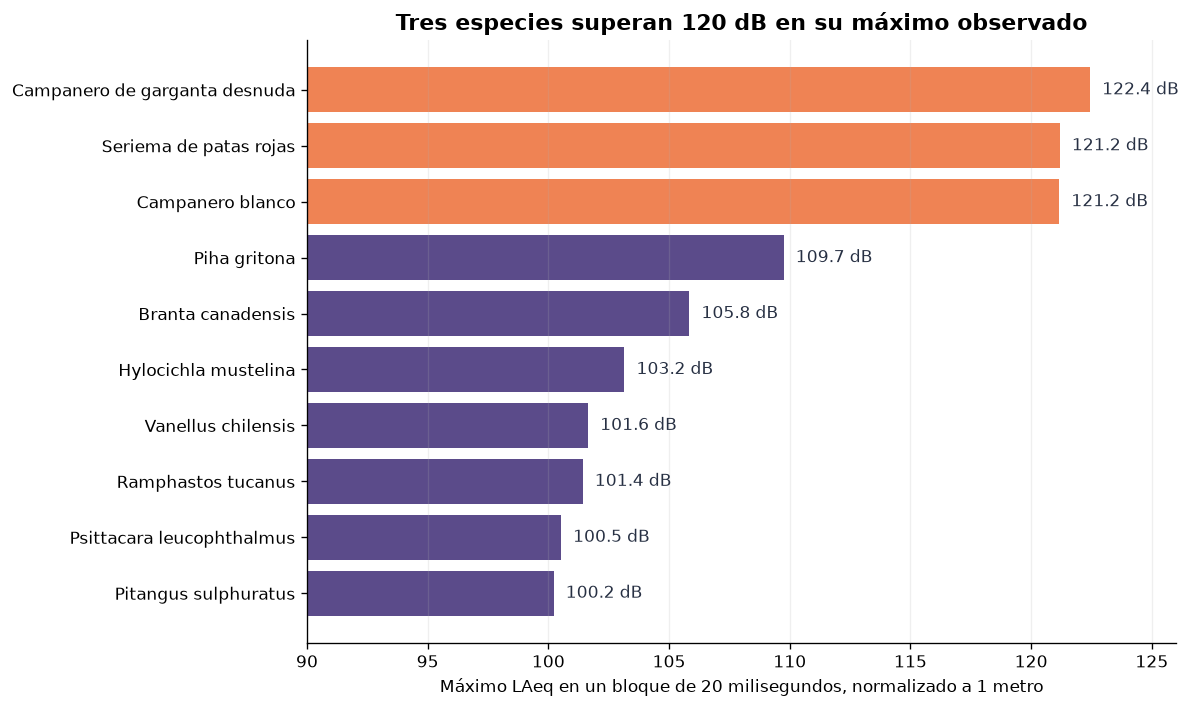

In [5]:
# selecciono las diez especies con el máximo LAeq más alto
top_observado = aves.nlargest(10, 'LAeq_max').sort_values('LAeq_max')

# destaco las tres especies que superan 120 dB en la muestra
colores = [
    color_highlight if valor >= 120 else color_nebula
    for valor in top_observado['LAeq_max']
]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_observado['nombre_legible'], top_observado['LAeq_max'], color=colores)

# anoto cada cifra para que la lectura no dependa de estimar la longitud de la barra
for indice, valor in enumerate(top_observado['LAeq_max']):
    ax.text(valor + 0.5, indice, f'{valor:.1f} dB', va='center', color=color_dark)

ax.set_title('Tres especies superan 120 dB en su máximo observado')
ax.set_xlabel('Máximo LAeq en un bloque de 20 milisegundos, normalizado a 1 metro')
ax.set_ylabel('')
ax.set_xlim(90, 126)
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

### Lectura del primer podio

El campanero de garganta desnuda ocupa el primer puesto con 122,4 dB. La seriema de patas rojas y el campanero blanco quedan prácticamente empatados alrededor de 121,2 dB.

Pero el ganador dispone de 7.724 lecturas. La seriema dispone de 870. El récord podría mezclar dos cosas: la capacidad de producir sonidos extremos y la cantidad de oportunidades que tuve para encontrarlos.

## El experimento justo: 30 oportunidades para cada especie

Los autores publicaron una segunda medida, `LAeq_max30`. La obtuvieron tomando repetidamente muestras de 30 lecturas por especie y estimando el máximo comparable.

La idea se parece a comparar goleadores después de igualar el número de partidos. No demuestra qué ave posee el límite anatómico más alto, pero evita que una especie gane solo porque fue observada muchas más veces.

Los dos paneles muestran el podio antes y después de igualar las oportunidades.

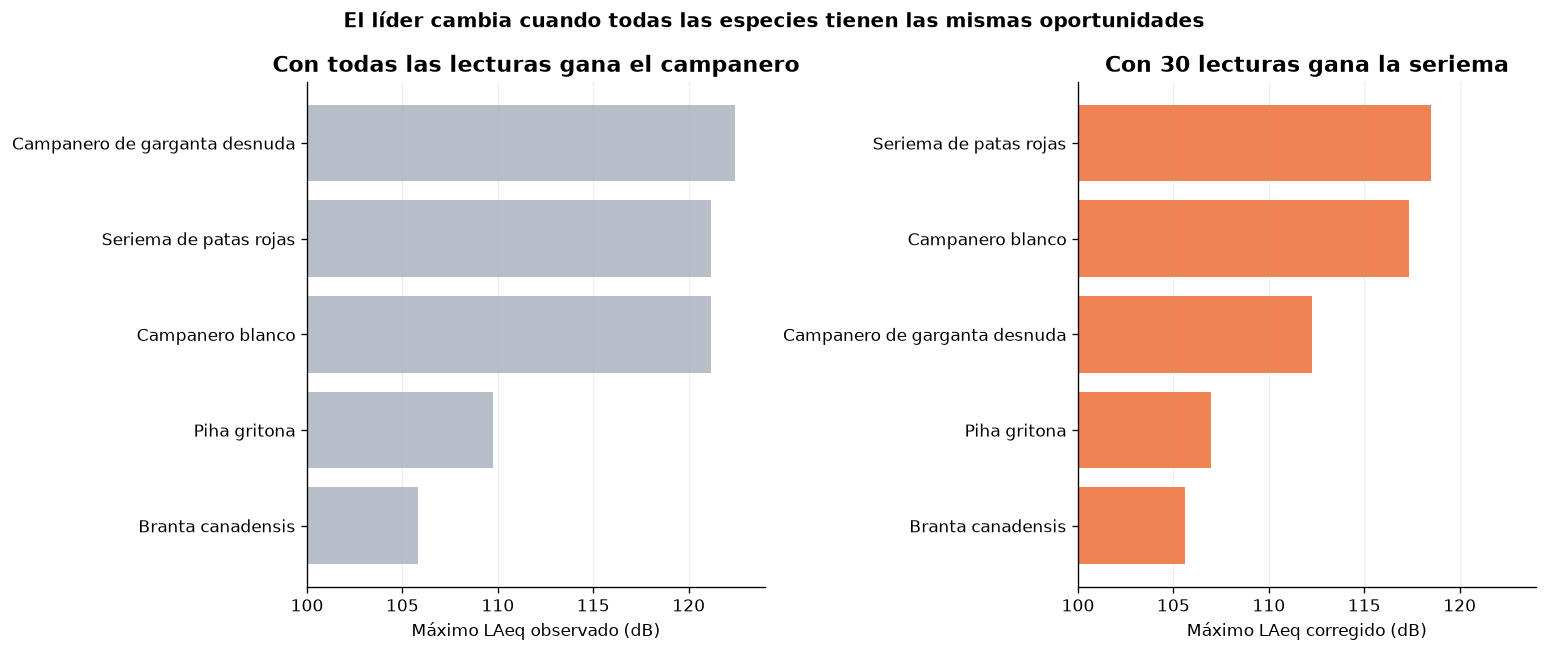

,especie,lecturas LAeq,máximo observado,máximo con 30 lecturas,pico instantáneo
12,Seriema de patas rojas,870,121.2,118.5,126.5
68,Campanero blanco,3758,121.2,117.3,128.9
69,Campanero de garganta desnuda,7724,122.4,112.3,130.9


In [6]:
# preparo los cinco primeros puestos con la medida observada y la corregida
podio_observado = aves.nlargest(5, 'LAeq_max').sort_values('LAeq_max')
podio_corregido = aves.nlargest(5, 'LAeq_max30').sort_values('LAeq_max30')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True)

# dibujo el podio basado en todas las lecturas disponibles
axes[0].barh(
    podio_observado['nombre_legible'],
    podio_observado['LAeq_max'],
    color=color_muted,
)
axes[0].set_title('Con todas las lecturas gana el campanero')
axes[0].set_xlabel('Máximo LAeq observado (dB)')

# dibujo el podio después de igualar a 30 lecturas por especie
axes[1].barh(
    podio_corregido['nombre_legible'],
    podio_corregido['LAeq_max30'],
    color=color_highlight,
)
axes[1].set_title('Con 30 lecturas gana la seriema')
axes[1].set_xlabel('Máximo LAeq corregido (dB)')

# mantengo la misma escala para que la comparación visual sea honesta
for ax in axes:
    ax.set_xlim(100, 124)
    ax.set_ylabel('')
    ax.grid(axis='x', alpha=0.2)

plt.suptitle('El líder cambia cuando todas las especies tienen las mismas oportunidades', fontweight='bold')
plt.tight_layout()
plt.show()

# muestro las cifras exactas de las tres protagonistas
protagonistas = aves.loc[
    aves['species'].isin(['Procnias_nudicollis', 'Cariama_cristata', 'Procnias_albus']),
    ['nombre_legible', 'LAeq_n.points', 'LAeq_max', 'LAeq_max30', 'LApeak_max'],
].sort_values('LAeq_max30', ascending=False)

tabla_protagonistas = protagonistas.rename(columns={
    'nombre_legible': 'especie',
    'LAeq_n.points': 'lecturas LAeq',
    'LAeq_max': 'máximo observado',
    'LAeq_max30': 'máximo con 30 lecturas',
    'LApeak_max': 'pico instantáneo',
}).copy()

# redondeo solo la presentación y conservo los cálculos originales sin cambios
columnas_db = ['máximo observado', 'máximo con 30 lecturas', 'pico instantáneo']
tabla_protagonistas[columnas_db] = tabla_protagonistas[columnas_db].round(1)
tabla_protagonistas['lecturas LAeq'] = tabla_protagonistas['lecturas LAeq'].astype(int)
display(tabla_protagonistas)

### El récord no desaparece, pero cambia de significado

Con todos los fragmentos disponibles, el campanero de garganta desnuda alcanza el máximo más alto. Al limitar la comparación a 30 lecturas, la seriema de patas rojas pasa al primer puesto con 118,5 dB y el campanero blanco queda segundo con 117,3 dB.

El campanero de garganta desnuda cae a 112,3 dB en la comparación igualada. Sigue dentro del grupo extremo, pero ya no gana.

Este es el nuevo punto de vista del análisis: **“el ave más ruidosa” no es una propiedad que pueda separarse del método utilizado para escucharla**.

## Cuantas más oportunidades, mayor puede ser el extremo

Para cada especie calculo la diferencia entre el máximo observado y el máximo corregido a 30 lecturas. Una diferencia grande indica que el récord bruto dependía mucho de disponer de numerosas oportunidades.

En el gráfico, cada punto es una especie. El eje horizontal utiliza una escala logarítmica: cada salto representa muchas más lecturas, no una suma constante.

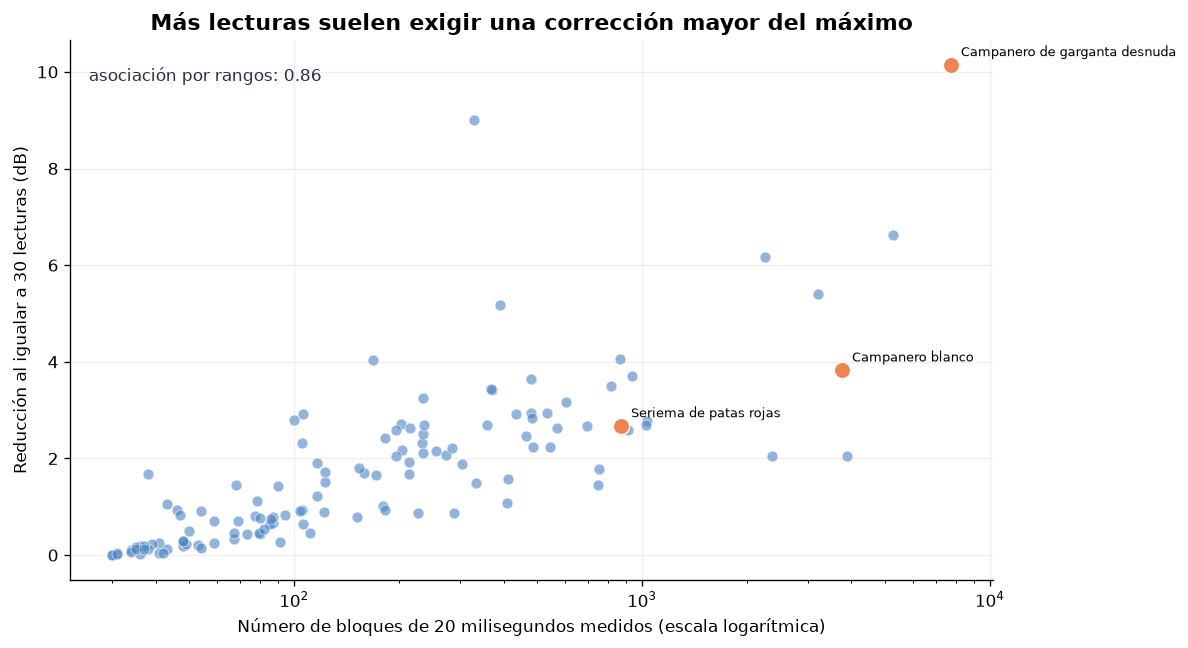

In [7]:
# calculo cuánto baja cada máximo después de igualar el esfuerzo de muestreo
aves['correccion_db'] = aves['LAeq_max'] - aves['LAeq_max30']

# calculo una asociación por rangos sin necesitar una librería estadística adicional
rango_lecturas = aves['LAeq_n.points'].rank()
rango_correccion = aves['correccion_db'].rank()
correlacion_muestreo = np.corrcoef(rango_lecturas, rango_correccion)[0, 1]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(
    aves['LAeq_n.points'],
    aves['correccion_db'],
    s=42,
    alpha=0.62,
    color=color_secondary,
    edgecolor='white',
    linewidth=0.5,
)

# destaco las tres especies del podio para conectar este gráfico con el anterior
for _, fila in aves.loc[
    aves['species'].isin(['Procnias_nudicollis', 'Cariama_cristata', 'Procnias_albus'])
].iterrows():
    ax.scatter(
        fila['LAeq_n.points'],
        fila['correccion_db'],
        s=95,
        color=color_highlight,
        edgecolor='white',
        linewidth=0.8,
        zorder=3,
    )
    ax.annotate(
        fila['nombre_legible'],
        (fila['LAeq_n.points'], fila['correccion_db']),
        xytext=(6, 5),
        textcoords='offset points',
        fontsize=8,
    )

ax.set_xscale('log')
ax.set_title('Más lecturas suelen exigir una corrección mayor del máximo')
ax.set_xlabel('Número de bloques de 20 milisegundos medidos (escala logarítmica)')
ax.set_ylabel('Reducción al igualar a 30 lecturas (dB)')
ax.grid(alpha=0.2)
ax.text(
    0.02,
    0.95,
    f'asociación por rangos: {correlacion_muestreo:.2f}',
    transform=ax.transAxes,
    va='top',
    color=color_dark,
)
plt.tight_layout()
plt.show()

### Qué significa la asociación de 0,86

La relación es fuerte: las especies con más lecturas tienden a perder más decibelios cuando igualo el esfuerzo de muestreo. Esto no demuestra que medir más *cause* un canto más fuerte. Demuestra algo más sencillo: buscar durante más tiempo aumenta la posibilidad de encontrar un extremo raro.

El campanero de garganta desnuda pierde unos 10,2 dB al pasar de 7.724 lecturas a la comparación común. La seriema pierde unos 2,7 dB. Esa diferencia basta para invertir el primer puesto.

## La maquinaria del volumen: cuerpo y pico

Ahora utilizo el máximo corregido, porque quiero comparar especies con el mismo número de oportunidades.

El primer panel relaciona el sonido con la masa corporal. Uso una escala logarítmica porque en la muestra conviven aves de pocos gramos con otras de varios kilos. El segundo panel compara el sonido con la anchura máxima de la abertura del pico.

La línea solo resume la tendencia general. No convierte una asociación en una causa.

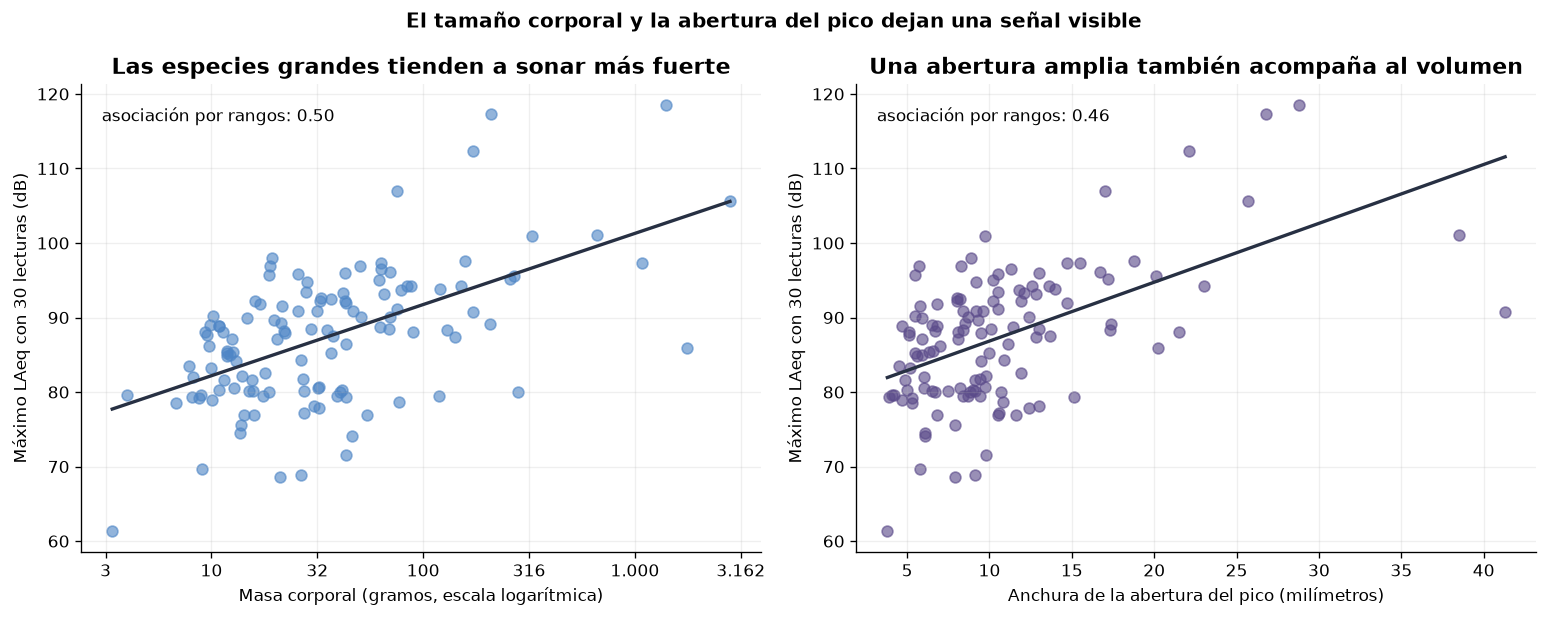

In [8]:
# preparo una función sencilla para calcular asociaciones por rangos
def correlacion_por_rangos(serie_x, serie_y):
    return np.corrcoef(serie_x.rank(), serie_y.rank())[0, 1]


# calculo las asociaciones descriptivas con la medida corregida
correlacion_masa = correlacion_por_rangos(aves['body.mass'], aves['LAeq_max30'])
correlacion_pico = correlacion_por_rangos(aves['gape.width'], aves['LAeq_max30'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# represento la masa en logaritmos para comparar tamaños muy distintos
masa_log = np.log10(aves['body.mass'])
axes[0].scatter(masa_log, aves['LAeq_max30'], color=color_secondary, alpha=0.62, s=42)
coeficientes_masa = np.polyfit(masa_log, aves['LAeq_max30'], 1)
eje_masa = np.linspace(masa_log.min(), masa_log.max(), 100)
axes[0].plot(eje_masa, np.polyval(coeficientes_masa, eje_masa), color=color_dark, linewidth=2)
axes[0].set_title('Las especies grandes tienden a sonar más fuerte')
axes[0].set_xlabel('Masa corporal (gramos, escala logarítmica)')
axes[0].set_ylabel('Máximo LAeq con 30 lecturas (dB)')
axes[0].set_xticks([0.5, 1, 1.5, 2, 2.5, 3, 3.5])
axes[0].set_xticklabels(['3', '10', '32', '100', '316', '1.000', '3.162'])

# represento la abertura del pico con su tendencia descriptiva
axes[1].scatter(aves['gape.width'], aves['LAeq_max30'], color=color_nebula, alpha=0.62, s=42)
coeficientes_pico = np.polyfit(aves['gape.width'], aves['LAeq_max30'], 1)
eje_pico = np.linspace(aves['gape.width'].min(), aves['gape.width'].max(), 100)
axes[1].plot(eje_pico, np.polyval(coeficientes_pico, eje_pico), color=color_dark, linewidth=2)
axes[1].set_title('Una abertura amplia también acompaña al volumen')
axes[1].set_xlabel('Anchura de la abertura del pico (milímetros)')
axes[1].set_ylabel('Máximo LAeq con 30 lecturas (dB)')

# anoto la fuerza de cada relación sin presentarla como una prueba causal
axes[0].text(0.03, 0.95, f'asociación por rangos: {correlacion_masa:.2f}', transform=axes[0].transAxes, va='top')
axes[1].text(0.03, 0.95, f'asociación por rangos: {correlacion_pico:.2f}', transform=axes[1].transAxes, va='top')

for ax in axes:
    ax.grid(alpha=0.2)

plt.suptitle('El tamaño corporal y la abertura del pico dejan una señal visible', fontweight='bold')
plt.tight_layout()
plt.show()

### Una pista física, no una receta

La masa corporal presenta una asociación por rangos de 0,50 con el máximo corregido. La abertura del pico alcanza 0,46. Son relaciones moderadas y visibles, no reglas sin excepciones.

La explicación propuesta por los investigadores es mecánica: un cuerpo mayor puede alojar músculos capaces de comprimir más aire, y una abertura amplia puede proyectar mejor el sonido. El artículo científico utilizó modelos que tienen en cuenta el parentesco evolutivo entre especies. Mi gráfico es deliberadamente más sencillo y solo confirma que la señal básica también aparece en los datos sin procesar.

## ¿Vivir entre árboles o tener varias parejas obliga a gritar?

El equipo esperaba que las voces más fuertes pudieran aparecer en aves con peor capacidad de vuelo, habitantes de medios densos o especies polígamas.

Para comprobar si existe una separación evidente, comparo:

- movilidad aérea y volumen;
- hábitats abiertos y densos;
- especies no polígamas y polígamas.

En los diagramas de caja, la línea central marca la mediana y la caja contiene la mitad central de las especies. Mucho solapamiento significa que el factor no permite distinguir bien los grupos por sí solo.

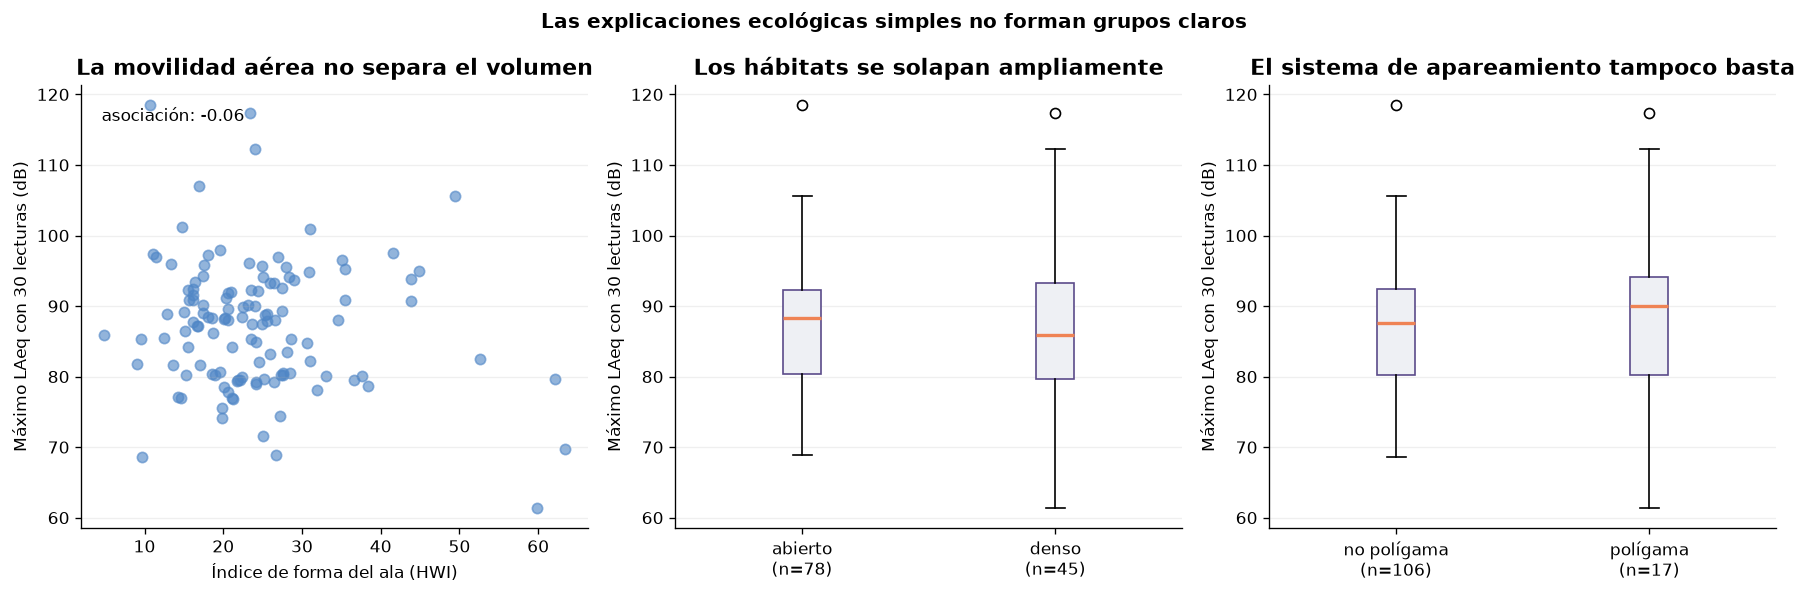

In [9]:
# calculo la relación descriptiva entre movilidad aérea y volumen
correlacion_vuelo = correlacion_por_rangos(aves['HWI'], aves['LAeq_max30'])

# separo los grupos ecológicos sin ocultar sus tamaños distintos
habitat_abierto = aves.loc[aves['habitat.density'].eq(0), 'LAeq_max30']
habitat_denso = aves.loc[aves['habitat.density'].eq(1), 'LAeq_max30']
no_poligamas = aves.loc[aves['polygamy'].eq(0), 'LAeq_max30']
poligamas = aves.loc[aves['polygamy'].eq(1), 'LAeq_max30']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# muestro la ausencia de una pendiente clara con el índice de movilidad
axes[0].scatter(aves['HWI'], aves['LAeq_max30'], color=color_secondary, alpha=0.62, s=38)
axes[0].set_title('La movilidad aérea no separa el volumen')
axes[0].set_xlabel('Índice de forma del ala (HWI)')
axes[0].set_ylabel('Máximo LAeq con 30 lecturas (dB)')
axes[0].text(0.04, 0.95, f'asociación: {correlacion_vuelo:.2f}', transform=axes[0].transAxes, va='top')

# comparo hábitats y mantengo visibles los tamaños de muestra
axes[1].boxplot(
    [habitat_abierto, habitat_denso],
    tick_labels=[f'abierto\n(n={len(habitat_abierto)})', f'denso\n(n={len(habitat_denso)})'],
    patch_artist=True,
    boxprops={'facecolor': color_light, 'edgecolor': color_nebula},
    medianprops={'color': color_highlight, 'linewidth': 2},
)
axes[1].set_title('Los hábitats se solapan ampliamente')
axes[1].set_ylabel('Máximo LAeq con 30 lecturas (dB)')

# comparo los sistemas de apareamiento y explicito el grupo pequeño
axes[2].boxplot(
    [no_poligamas, poligamas],
    tick_labels=[f'no polígama\n(n={len(no_poligamas)})', f'polígama\n(n={len(poligamas)})'],
    patch_artist=True,
    boxprops={'facecolor': color_light, 'edgecolor': color_nebula},
    medianprops={'color': color_highlight, 'linewidth': 2},
)
axes[2].set_title('El sistema de apareamiento tampoco basta')
axes[2].set_ylabel('Máximo LAeq con 30 lecturas (dB)')

for ax in axes:
    ax.grid(axis='y', alpha=0.2)

plt.suptitle('Las explicaciones ecológicas simples no forman grupos claros', fontweight='bold')
plt.tight_layout()
plt.show()

### La ausencia de un patrón también es un resultado

La movilidad aérea muestra una asociación prácticamente nula con el volumen corregido. Los grupos de hábitat y apareamiento se superponen ampliamente.

No puedo concluir que estos factores no importen nunca. La categoría polígama solo contiene 17 especies, las relaciones evolutivas complican la comparación y una variable binaria simplifica ecosistemas muy distintos. La conclusión prudente coincide con el estudio: los datos no ofrecen apoyo inequívoco para estas explicaciones generales.

## La cadena completa de evidencia

| Nivel | Resultado | Qué permite decir |
|---|---|---|
| **Dato observado** | El campanero de garganta desnuda alcanza 122,4 dB LAeq y 130,9 dB de pico. | Es el máximo registrado en esta muestra con todas las lecturas disponibles. |
| **Corrección publicada** | Con 30 lecturas por especie, la seriema llega a 118,5 dB, el campanero blanco a 117,3 y el campanero de garganta desnuda a 112,3. | El primer puesto depende del esfuerzo de muestreo. |
| **EDA de Nebula** | El número de lecturas y el tamaño de la corrección tienen una asociación por rangos de 0,86. | Buscar más veces aumenta la posibilidad de encontrar un extremo raro. |
| **EDA de Nebula** | Masa y abertura del pico muestran asociaciones moderadas con el volumen corregido. | Existe una pista morfológica visible, pero no una regla causal. |
| **Resultado del estudio** | Los modelos evolutivos respaldan tamaño y abertura, pero no ofrecen apoyo claro para movilidad, hábitat o poligamia. | Se conoce parte del “cómo”, pero el “por qué” evolutivo sigue abierto. |

## Comprobaciones, limitaciones y explicaciones alternativas

- Este EDA utiliza el archivo suplementario de los autores; no vuelve a medir grabaciones originales.
- `LAeq_max30` corrige el número de fragmentos, pero no iguala el número de individuos. La muestra va de 1 a 18 individuos como mínimo por especie.
- Treinta lecturas representan solo 0,6 segundos acumulados de bloques de 20 milisegundos. La medida sirve para comparar extremos, no para describir un canto completo.
- Las medidas están normalizadas a un metro. No representan necesariamente lo que escucha una persona situada a otra distancia.
- Un máximo breve no equivale a una exposición prolongada con el mismo nivel acústico.
- Las correlaciones simples de este notebook no sustituyen los modelos filogenéticos del artículo, que consideran que especies emparentadas no son observaciones completamente independientes.
- La abertura del pico procede de varias fuentes y su definición exacta varía entre ellas.
- El archivo de metadatos contiene descripciones inconsistentes para algunas columnas ecológicas. Para interpretarlas sigo el artículo y la documentación del estudio, no esas etiquetas aisladas.
- Las 123 especies no forman una muestra aleatoria de todas las aves del planeta. El récord significa “la más alta entre las especies medidas con este protocolo”, no una campeona definitiva de las más de 10.000 especies conocidas.

## Qué sé, qué no sé y por qué importa

### Lo que puedo afirmar

Tres especies superaron 120 dB LAeq en sus máximos observados. El campanero de garganta desnuda produjo el valor bruto más alto. Cuando igualo todas las especies a 30 lecturas, la seriema de patas rojas ocupa el primer puesto.

Las especies más grandes y las que abren más el pico tienden a alcanzar mayores amplitudes. El patrón no aparece con la misma claridad para movilidad aérea, densidad del hábitat o sistema de apareamiento.

### Lo que todavía no puedo afirmar

No puedo coronar de manera definitiva al ave más ruidosa del mundo. El resultado depende de qué especies fueron medidas, cuántos individuos participaron, cuántas lecturas se tomaron y qué definición de “más ruidosa” elijo.

Tampoco puedo decir que un cuerpo grande o un pico ancho causen por sí solos una voz potente. Son pistas compatibles con una explicación física, no una demostración mecánica individual.

### Por qué importa

Los récords científicos parecen cifras simples, pero esconden decisiones de medida. Preguntar cuántas oportunidades tuvo cada competidor convierte un titular llamativo en una lección general sobre datos: **antes de comparar extremos, debo igualar la posibilidad de encontrarlos**.

## Fuentes

- Menezes, J. C. T. y Podos, J. (2026). *Evolutionary drivers of vocal amplitude in birds*. **Evolution**, qpag153. https://doi.org/10.1093/evolut/qpag153
- Archivo suplementario `DataS1.xlsx` y tablas S1-S2 publicados junto al artículo.
- University of Massachusetts Amherst (2026). *UMass Amherst Biologists May Have Discovered Two of the World’s Loudest Birds*. https://www.umass.edu/news/article/umass-amherst-biologists-may-have-discovered-two-worlds-loudest-birds

Fecha de consulta y preparación del EDA: 13 de octubre de 2026.